Sweeping Ropt to reveal the physical trade-off...
Ropt=5.00 Ω: Pout=2034.9 mW, η=90.71%, I_dc=460.9 mA
Ropt=6.00 Ω: Pout=1724.2 mW, η=92.14%, I_dc=384.2 mA
Ropt=7.00 Ω: Pout=1490.5 mW, η=93.16%, I_dc=328.2 mA
Ropt=8.00 Ω: Pout=1308.1 mW, η=93.92%, I_dc=285.5 mA
Ropt=9.00 Ω: Pout=1162.3 mW, η=94.49%, I_dc=252.0 mA
Ropt=10.00 Ω: Pout=1042.7 mW, η=94.94%, I_dc=224.8 mA
Ropt=11.00 Ω: Pout=944.2 mW, η=95.29%, I_dc=202.6 mA
Ropt=12.00 Ω: Pout=861.1 mW, η=95.57%, I_dc=184.1 mA
Ropt=13.00 Ω: Pout=784.4 mW, η=95.81%, I_dc=167.1 mA
Ropt=14.00 Ω: Pout=728.9 mW, η=95.96%, I_dc=154.9 mA

### ROPT TRADE-OFF SUMMARY

 Ropt   Pout (mW)  Efficiency (%)  Peak i_sw (A)  DC Current (mA)  Cext (pF)    L1 (nH)    L2 (nH)    C2 (pF)  V_turnon (mV)
  5.0 2034.860345       90.708541       1.290520       460.875297 426.074657  99.112988 271.819382 436.899255       0.005937
  6.0 1724.196673       92.139584       1.071326       384.172716 360.117152 102.340423 275.050153 451.219614       0.006981
  7.0 1490.5227

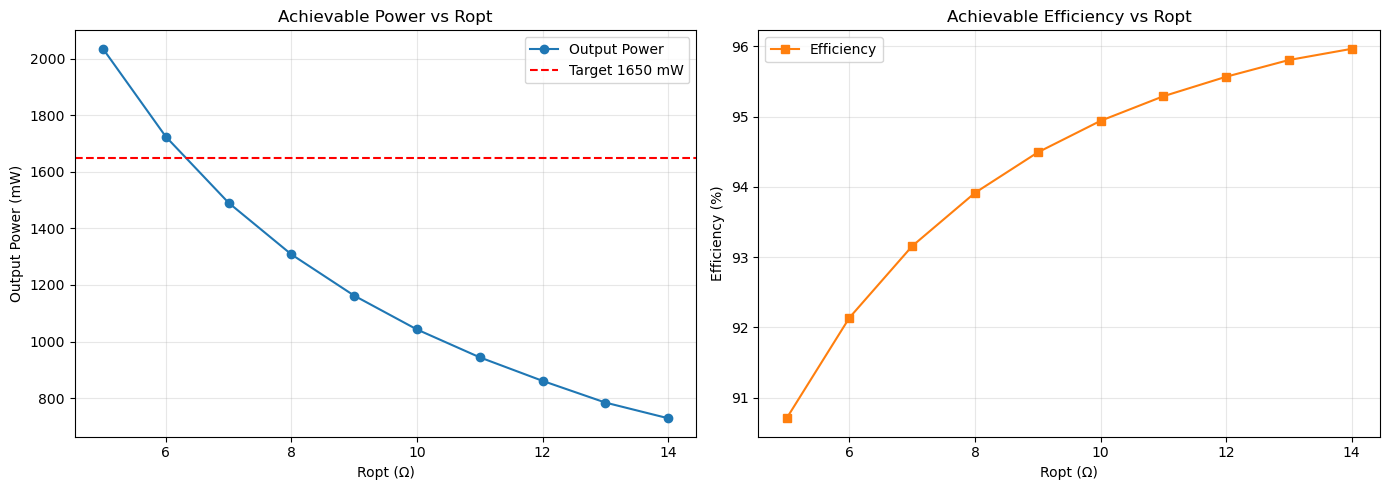

In [1]:
# =============================================================================
# CONSOLIDATED EPC2037 GaN CLASS-E AMPLIFIER NOTEBOOK
# Trade-off Sweep: Ropt vs Achievable Power and Efficiency
# =============================================================================
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, cumulative_trapezoid
from scipy.optimize import brentq, minimize
from scipy.interpolate import PchipInterpolator
import pandas as pd
import warnings

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# --- Specs ---
VDD, POUT_TARGET, F0 = 4.85, 1.65, 14.0e6
W0, T, TH = 2*np.pi*F0, 1/F0, 1/(2*F0)
VDS_MAX, ID_MAX = 100.0, 1.7
RON_25 = 0.400
QG, VG = 115e-12, 5.0
PGATE = QG*VG*F0
COSS_50, QOSS_50, COSS_TR = 6.5e-12, 600e-12, 12e-12

# Analytical starting point
a = 2/np.sqrt(np.pi**2 + 4)
Ropt_ana = 2*a**2*VDD**2/POUT_TARGET
phi = np.pi - np.arctan(2/np.pi)
IR_norm = np.sqrt(2/(2*a**2))
IDC_norm = a*IR_norm
C_norm = (2*a**2/np.pi)/(2*a**2)
th = np.linspace(0, 2*np.pi, 200001)
vd_norm = np.zeros_like(th)
off = th >= np.pi
vd_norm[off] = (IDC_norm*(th[off]-np.pi) + IR_norm*(np.cos(th[off]+phi)-np.cos(np.pi+phi)))/C_norm
V1 = np.trapezoid(vd_norm*np.exp(-1j*th), th)/np.pi
I1 = IR_norm*np.exp(1j*(phi-np.pi/2))
KL = (V1/I1).imag/(V1/I1).real
L1_ana = KL*Ropt_ana/W0
L2_ana = 3.0*Ropt_ana/W0
C2_ana = 1/(W0**2*L2_ana)

# =============================================================================
# Datasheet & Coss Models
# =============================================================================
DS_FIG5_VDS = np.array([0, 5, 10, 15, 20, 25, 30, 40, 50, 60, 75, 100.])
DS_FIG5_COSS = 1e-12*np.array([22.0, 15.5, 11.5, 9.8, 8.5, 7.5, 7.0, 6.7, 6.5, 5.8, 5.1, 4.5])
_coss_dig = PchipInterpolator(DS_FIG5_VDS, DS_FIG5_COSS, extrapolate=False)
V_GRID = np.linspace(0, 150, 150001)
C_GRID_RAW = _coss_dig(np.clip(V_GRID, 0, 100))
Q_GRID_RAW = cumulative_trapezoid(C_GRID_RAW, V_GRID, initial=0)
Q_RAW_50 = Q_GRID_RAW[np.argmin(np.abs(V_GRID-50))]
CAL_A = (QOSS_50-Q_RAW_50)/25.0
C_GRID = C_GRID_RAW.copy()
C_GRID[V_GRID <= 50] += CAL_A*(1-V_GRID[V_GRID <= 50]/50)
Q_GRID = cumulative_trapezoid(C_GRID, V_GRID, initial=0)
E_GRID = cumulative_trapezoid(V_GRID*C_GRID, V_GRID, initial=0)
_coss_tab, _qoss_tab, _eoss_tab = PchipInterpolator(V_GRID, C_GRID), PchipInterpolator(V_GRID, Q_GRID), PchipInterpolator(V_GRID, E_GRID)

def coss_tab(v): return _coss_tab(np.clip(np.abs(v), 0, 150))
def qoss_tab(v): return np.sign(v)*_qoss_tab(np.abs(v))
def eoss_tab(v): return _eoss_tab(np.abs(v))

# =============================================================================
# Simulation Engine
# =============================================================================
class DeviceModel:
    def __init__(self, coss_f, qoss_f, eoss_f, Cext, Ron):
        self.coss_f, self.qoss_f, self.eoss_f = coss_f, qoss_f, eoss_f
        self.Cext, self.Ron = float(Cext), float(Ron)
        self._vg = np.linspace(0, 150, 150001)
        self._qg = self.Cext*self._vg + np.asarray(self.qoss_f(self._vg), float)
    def v_from_q(self, q):
        q = float(q)
        if abs(q) < 1e-30: return 0.0
        return np.sign(q)*float(np.interp(abs(q), self._qg, self._vg))

def cycle_nonlin(IDC, dev, LT_val, C2_val, Ropt_val, warmup=100, samples=400):
    def f_on(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL-vD/dev.Ron, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    def f_off(t, y):
        q, iL, v2 = y
        vD = dev.v_from_q(q)
        return [IDC-iL, (vD-v2-Ropt_val*iL)/LT_val, iL/C2_val]
    y = np.zeros(3)
    for _ in range(warmup):
        s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12)
        s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12)
        y = s2.y[:, -1]
    s1 = solve_ivp(f_on, (0, TH), y, method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    s2 = solve_ivp(f_off, (0, TH), s1.y[:, -1], method="LSODA", rtol=2e-8, atol=1e-12, dense_output=True)
    t1, t2 = np.linspace(0, TH, samples, endpoint=False), np.linspace(0, TH, samples, endpoint=False)
    y1, y2 = s1.sol(t1), s2.sol(t2)
    q = np.r_[y1[0], y2[0]]; iL = np.r_[y1[1], y2[1]]
    t = np.r_[t1, TH+t2]; vD = np.array([dev.v_from_q(z) for z in q]); iSW = np.r_[vD[:samples]/dev.Ron, np.zeros(samples)]
    return {"t": t, "v_D": vD, "i_L": iL, "i_sw": iSW, "v_avg": np.trapezoid(vD, t)/T,
            "v_turnon": float(dev.v_from_q(s2.y[0, -1])), "i_turnon": float(s2.y[1, -1])}

def solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=50, samples=200):
    def resid(I): return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup, samples=samples)["v_avg"] - VDD
    I = brentq(resid, 0.05*POUT_TARGET/VDD, 3.0*POUT_TARGET/VDD, xtol=1e-8)
    return cycle_nonlin(I, dev, LT_val, C2_val, Ropt_val, warmup=warmup*2, samples=samples*2), I

# =============================================================================
# Optimization Function for a Given Ropt
# =============================================================================
def optimize_for_Ropt(Ropt_val):
    x0_scaled = [247.33, 107.73, 280.44, 460.83]
    bounds_scaled = [(100, 500), (50, 250), (150, 450), (200, 900)]
    
    cache = {}
    def eval_design(x):
        key = tuple(np.round(x, 5))
        if key in cache: return cache[key]
        
        Cext, L1_val, L2_val, C2_val = x[0]*1e-12, x[1]*1e-9, x[2]*1e-9, x[3]*1e-12
        LT_val = L1_val + L2_val
        dev = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext, RON_25)
        
        try:
            h, I = solve_nonlin(dev, LT_val, C2_val, Ropt_val, warmup=20, samples=100)
            P_load = np.trapezoid(Ropt_val*h["i_L"]**2, h["t"])/T
            P_in = VDD * I
            eta = P_load / (P_in + PGATE)
            C_sh_tot = Cext + dev.coss_f(h["v_turnon"])
            dVdt = (I - h["i_turnon"]) / C_sh_tot
            res = (h["v_turnon"], dVdt, P_load, eta, P_in, np.max(h["i_sw"]), np.max(h["v_D"]))
        except Exception:
            res = (10.0, 10.0, 0.0, 0.0, 10.0, 10.0, 10.0)
            
        cache[key] = res
        return res

    def obj(x): return -eval_design(x)[3]
    def con_zvs(x): return eval_design(x)[0]
    def con_zds(x): return eval_design(x)[1] * 1e-8
    
    cons = [{'type': 'eq', 'fun': con_zvs}, {'type': 'eq', 'fun': con_zds}]
    res_opt = minimize(obj, x0_scaled, method='SLSQP', bounds=bounds_scaled, constraints=cons,
                       options={'maxiter': 150, 'eps': 1e-4})
    
    Cext_t, L1_t, L2_t, C2_t = res_opt.x[0]*1e-12, res_opt.x[1]*1e-9, res_opt.x[2]*1e-9, res_opt.x[3]*1e-12
    LT_t = L1_t + L2_t
    dev_tuned = DeviceModel(coss_tab, qoss_tab, eoss_tab, Cext_t, RON_25)
    h_tuned, I_tuned = solve_nonlin(dev_tuned, LT_t, C2_t, Ropt_val, warmup=500, samples=1600)
    
    P_load_final = np.trapezoid(Ropt_val*h_tuned["i_L"]**2, h_tuned["t"])/T
    P_in_final = VDD * I_tuned
    eta_final = P_load_final / (P_in_final + PGATE)
    
    return {
        "Ropt": Ropt_val,
        "Pout (mW)": P_load_final*1e3,
        "Efficiency (%)": eta_final*100,
        "Peak i_sw (A)": np.max(h_tuned["i_sw"]),
        "DC Current (mA)": I_tuned*1e3,
        "Cext (pF)": Cext_t*1e12,
        "L1 (nH)": L1_t*1e9,
        "L2 (nH)": L2_t*1e9,
        "C2 (pF)": C2_t*1e12,
        "V_turnon (mV)": h_tuned["v_turnon"]*1e3,
    }

# =============================================================================
# Sweep Ropt
# =============================================================================
print("Sweeping Ropt to reveal the physical trade-off...")
Ropt_values = np.linspace(5.0, 14.0, 10)
results = []

for r in Ropt_values:
    res = optimize_for_Ropt(r)
    results.append(res)
    print(f"Ropt={r:.2f} Ω: Pout={res['Pout (mW)']:.1f} mW, η={res['Efficiency (%)']:.2f}%, I_dc={res['DC Current (mA)']:.1f} mA")

df = pd.DataFrame(results)
print("\n### ROPT TRADE-OFF SUMMARY\n")
print(df.to_string(index=False))

# =============================================================================
# Plotting the Trade-off
# =============================================================================
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(df["Ropt"], df["Pout (mW)"], "o-", label="Output Power")
ax[0].axhline(1650, color="red", ls="--", label="Target 1650 mW")
ax[0].set_xlabel("Ropt (Ω)")
ax[0].set_ylabel("Output Power (mW)")
ax[0].set_title("Achievable Power vs Ropt")
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(df["Ropt"], df["Efficiency (%)"], "s-", color="C1", label="Efficiency")
ax[1].set_xlabel("Ropt (Ω)")
ax[1].set_ylabel("Efficiency (%)")
ax[1].set_title("Achievable Efficiency vs Ropt")
ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()